# Complex shear-modulus fields from measured harmonic waves

## 1. Problem
We reconstruct frequency-dependent storage and loss modulus from a real BIOQIC multi-inclusion phantom. The selected published method is the algebraic Helmholtz inversion (AHI) baseline in Ragoza and Batmanghelich, MICCAI2023, [author manuscript](https://pmc.ncbi.nlm.nih.gov/articles/PMC11141115/). This notebook does not reproduce the paper's PINN training. Its active path implements the author-supported regularized direct baseline locally, then compares meaningful derivative choices on the same observations.

The spatial unknown is the complex modulus $G=G'+iG''$ in Pa. Both storage $G'$ and loss $G''$ are reconstructed at 80 and 100 Hz. No independently measured modulus truth is available. The source's hardcoded springpot material map is not used as truth or calibration.

In [1]:
from pathlib import Path
import os,sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import polynomial_kernels,relative_residual
from src import visualization as vis
waves,support,frequencies,coordinates=load_data()
original=np.load('notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False)['reconstruction'][0].transpose(0,3,2,1)
print('Native harmonic observations',waves.shape,'support',int(support.sum()),'frequencies Hz',frequencies)
zindex=12
print('Shown native slice z=',zindex,'at',coordinates[2][zindex]*1000,'mm; all 25 planes reconstructed.')

Native harmonic observations (2, 128, 80, 25, 3) support 144637 frequencies Hz [ 80. 100.]
Shown native slice z= 12 at 18.000000000000004 mm; all 25 planes reconstructed.


## 2. Data
The bound arrays retain the full 128×80×25 native grid, spacing 1.5 mm, and all three motion-encoded channels in their original z,x,y order. The observations are real phase-derived first temporal harmonics, not synthetic waves. Source processing uses circular phase smoothing, a y-directed phase gradient, the first of eight temporal Fourier harmonics, planar low-pass filtering and a spatially uniform amplitude multiplier. Absolute displacement calibration is not claimed.

The binary support comes from the magnitude image and the author's fixed interior rectangle, with 144637 included voxels. We independently reproduced that binary mask without inclusion labels; no output-dependent quality mask is introduced. The original sample is publicly offered for local analysis; redistribution rights were unspecified and are not inferred.

An upstream wrapper issue was detected before extraction: `preprocess(verbose=False)` passes False as a Gaussian sigma. The unchanged individual source functions were therefore called with their explicit documented defaults (sigma0.8 for geometry and0.65 for phase), and those exact processed observations were bound. Earlier exploratory zero-width results are archived separately and not used as the oracle.

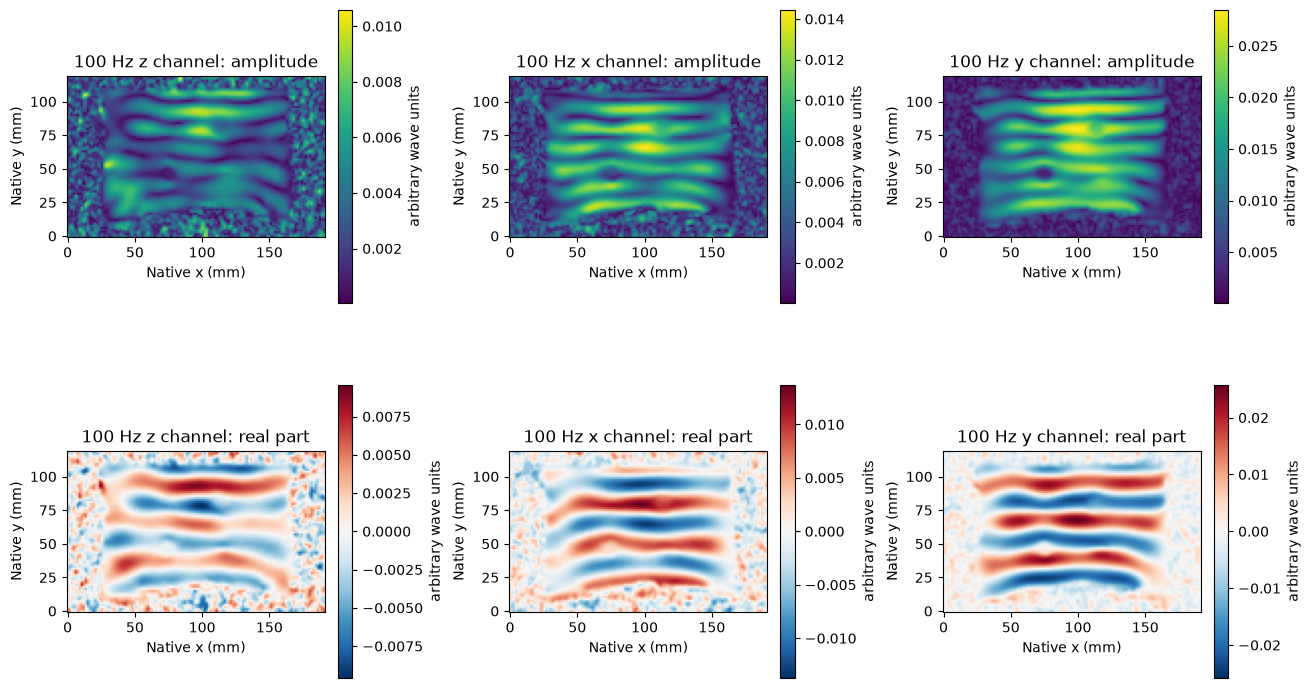

In [2]:
fig,axes=plt.subplots(2,3,figsize=(13,7.5),layout='constrained')
for c,name in enumerate(['z channel','x channel','y channel']):
    a=waves[1,:,:,zindex,c]
    vis.panel(axes[0,c],abs(a),f'100 Hz {name}: amplitude','arbitrary wave units')
    lim=float(abs(a.real).max());vis.panel(axes[1,c],a.real,f'100 Hz {name}: real part','arbitrary wave units','RdBu_r',(-lim,lim))
vis.save(fig,'01_measured_harmonic_wave_channels');plt.show()

## 3. Physics
For angular frequency $\omega=2\pi f$, density $\rho=1000$ kg/m³, channel $c$ and position $r$, the selected local planar model is

$$G(r,\omega)\Delta_{xy}U_c(r,\omega)+\rho\omega^2U_c(r,\omega)\simeq0.$$

$\Delta_{xy}$ sums second derivatives with respect to metre-valued x and y. It omits z derivatives, pressure and spatial gradients of modulus. A spatial derivative commutes with this equation only when its coefficients are locally constant, explaining why the phase-gradient wave can be used conditionally. Material boundaries and interference remain limitations. A common spatially uniform complex wave amplitude cancels ideally; the source's tiny absolute denominator stabilizer makes cancellation approximate numerically.

The original polar formulation selects $G''\geq0$ through an arccos phase branch. It is a source convention, not independent recovery of the propagation sign. Negative storage can still occur and remains included.

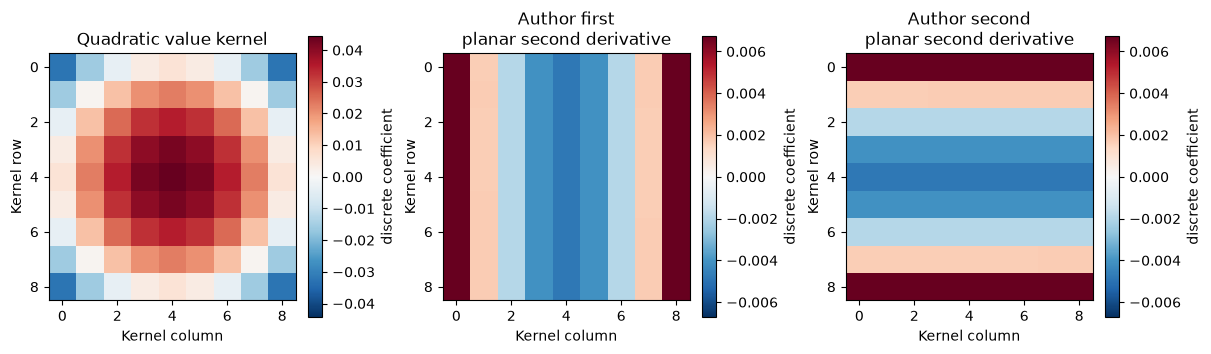

Kernel value sum: 1.0000000000000002 second derivative sums: 6.591949208711867e-17 6.765421556309548e-17


In [3]:
kernels=polynomial_kernels();fig,axes=plt.subplots(1,3,figsize=(12,3.6),layout='constrained')
for ax,key,title in zip(axes,[(0,0),(2,0),(0,2)],['Quadratic value kernel','Author first planar second derivative','Author second planar second derivative']):
    a=kernels[key];lim=float(abs(a).max());im=ax.imshow(a,cmap='RdBu_r',vmin=-lim,vmax=lim);ax.set(title=title.replace(' planar','\nplanar'),xlabel='Kernel column',ylabel='Kernel row');fig.colorbar(im,ax=ax,label='discrete coefficient',shrink=.8)
vis.save(fig,'02_explicit_polynomial_kernels');plt.show()
print('Kernel value sum:',kernels[(0,0)].sum(),'second derivative sums:',kernels[(2,0)].sum(),kernels[(0,2)].sum())

## 4. Method
We fit total-degree quadratic polynomials on each reflected 9×9 x/y neighborhood. Pseudoinverse rows and derivative factorials define explicit value and derivative convolutions. The wave is first smoothed; second derivatives are then applied to that smoothed wave, exactly as the selected original baseline. Derivative spacing is in metres. A reflected median-relative source filter regularizes the reciprocal Laplacian, treating its magnitude and phase separately.

For regularized wave $u_c$ and Laplacian $L_c$, define

$$A=\frac{\rho\omega^2\sum_c|u_c|}{\sum_c|L_c|+\epsilon},\quad
\phi=\arccos\frac{-\sum_c(\Re u_c\Re L_c+\Im u_c\Im L_c)}{\sum_c|u_c||L_c|+\epsilon},\quad G=Ae^{i\phi}.$$

Here $A$ is modulus magnitude in Pa, $\phi\in[0,\pi]$ is its phase, and $\epsilon=10^{-8}$ is the original numerical stabilizer in the corresponding wave units. This is direct algebra, not iterative optimization. No learned model, fitted material prior, positivity clipping of storage or new spatial mask is introduced. Derivatives use the entire observed grid; support is applied only to the output.

In [4]:
begin=time.perf_counter();modulus,filtered,laplacian=reconstruct(waves,frequencies,coordinates,support);runtime=time.perf_counter()-begin
Path('output').mkdir(exist_ok=True);np.savez_compressed('output/reconstruction.npz',reconstruction=modulus.transpose(0,3,2,1)[None])
agreement=[];residuals=[]
for k,f in enumerate(frequencies):
    row=dict(frequency_Hz=float(f),storage=vis.scalar_metrics(modulus[k].real[support],original[k].real[support]),loss=vis.scalar_metrics(modulus[k].imag[support],original[k].imag[support]))
    agreement.append(row);residuals.append(relative_residual(modulus[k],filtered[k],laplacian[k],f,support))
print(json.dumps(dict(fresh_seconds=runtime,agreement_with_original=agreement,relative_vector_helmholtz_residuals=residuals),indent=2))

{
  "fresh_seconds": 1.7412407000083476,
  "agreement_with_original": [
    {
      "frequency_Hz": 80.0,
      "storage": {
        "ncc": 1.0,
        "nrmse": 0.0
      },
      "loss": {
        "ncc": 0.9999999999999999,
        "nrmse": 0.0
      }
    },
    {
      "frequency_Hz": 100.0,
      "storage": {
        "ncc": 1.0,
        "nrmse": 0.0
      },
      "loss": {
        "ncc": 0.9999999999999998,
        "nrmse": 0.0
      }
    }
  ],
  "relative_vector_helmholtz_residuals": [
    0.2501509233855453,
    0.2736138916494486
  ]
}


## 5. Results
First compare separately identified reproduced-original and fresh-local estimates. The original is a standard-method reference, not actual material truth. Display maps use fixed full-support 1st–99th percentile ranges to make spatial structure visible; colorbar triangles identify display saturation. Only display ranges are limited: all metrics, residuals, histograms and numerical sources retain every supported value, including extreme and negative estimates. The exact difference panels use symmetric limits about zero.

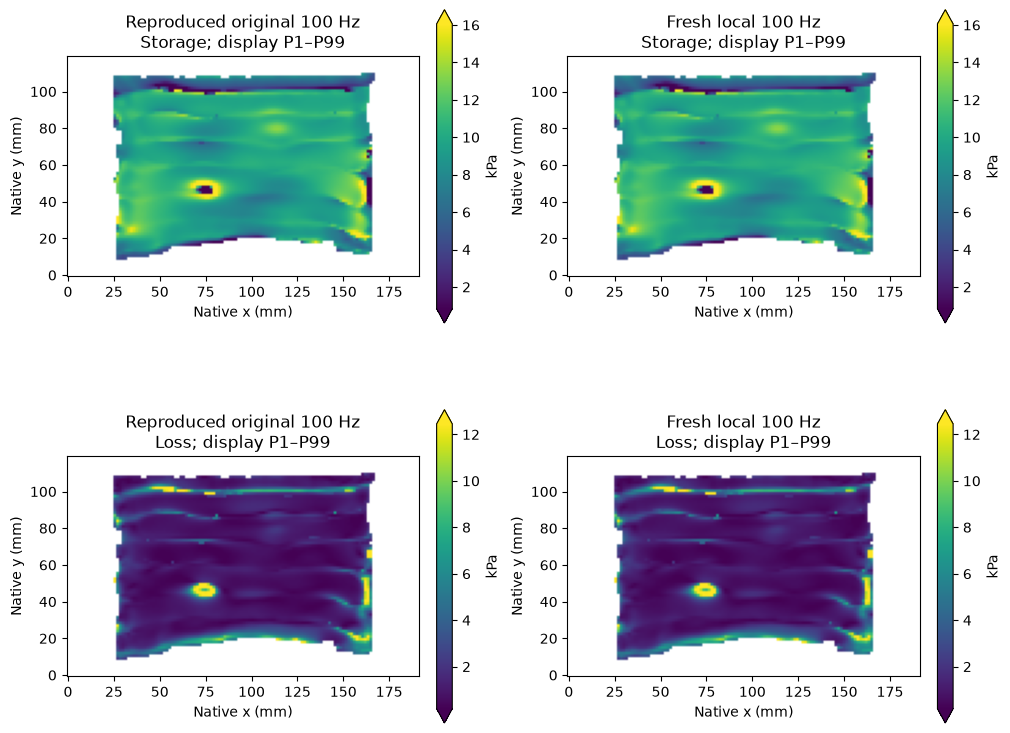

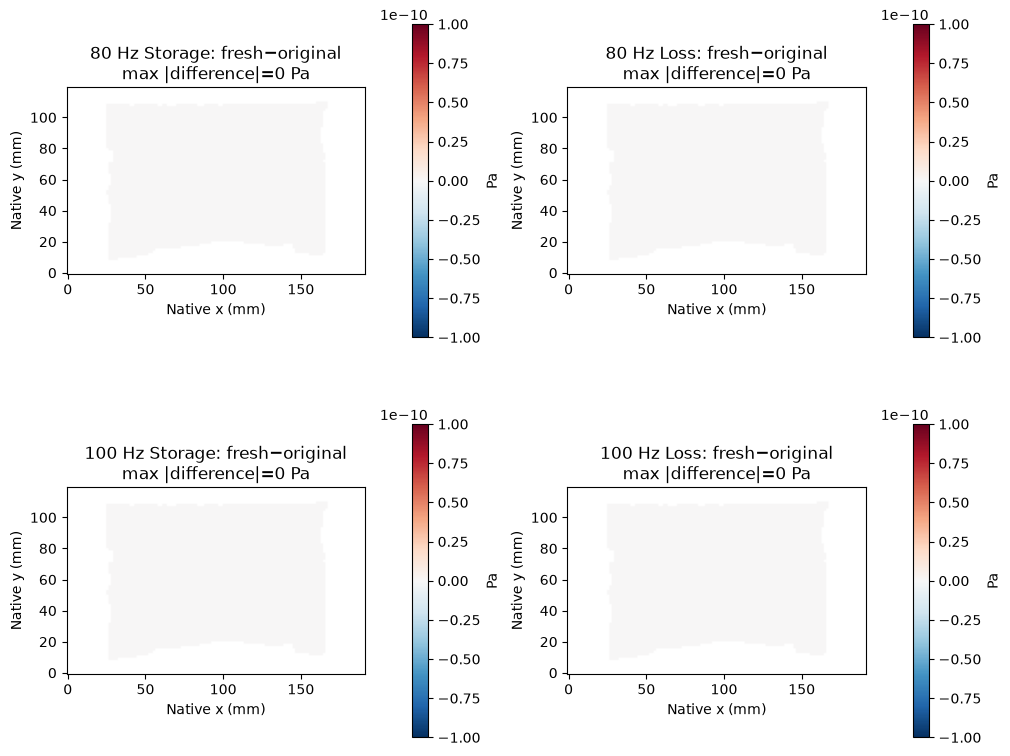

In [5]:
display_limits={}
fig,axes=plt.subplots(2,2,figsize=(10,8),layout='constrained')
for row,(extract,name) in enumerate([(np.real,'Storage'),(np.imag,'Loss')]):
    limit=tuple(np.quantile(extract(original[1])[support]/1000,[.01,.99]));display_limits[name]=limit
    for col,(a,title) in enumerate([(original[1],'Reproduced original'),(modulus[1],'Fresh local')]):
        image=np.where(support[:,:,zindex],extract(a[:,:,zindex])/1000,np.nan)
        vis.panel(axes[row,col],image,f'{title} 100 Hz\n{name}; display P1–P99','kPa',limits=limit)
vis.save(fig,'03_original_and_fresh_storage_loss');plt.show()
fig,axes=plt.subplots(2,2,figsize=(10,8),layout='constrained')
for k,f in enumerate(frequencies):
    for j,(extract,name) in enumerate([(np.real,'Storage'),(np.imag,'Loss')]):
        difference=extract(modulus[k]-original[k]);limit=max(float(abs(difference).max()),1e-10)
        vis.panel(axes[k,j],np.where(support[:,:,zindex],difference[:,:,zindex],np.nan),f'{f:.0f} Hz {name}: fresh−original\nmax |difference|={abs(difference).max():.2g} Pa','Pa','RdBu_r',(-limit,limit))
vis.save(fig,'04_bitwise_complex_component_comparison');plt.show()

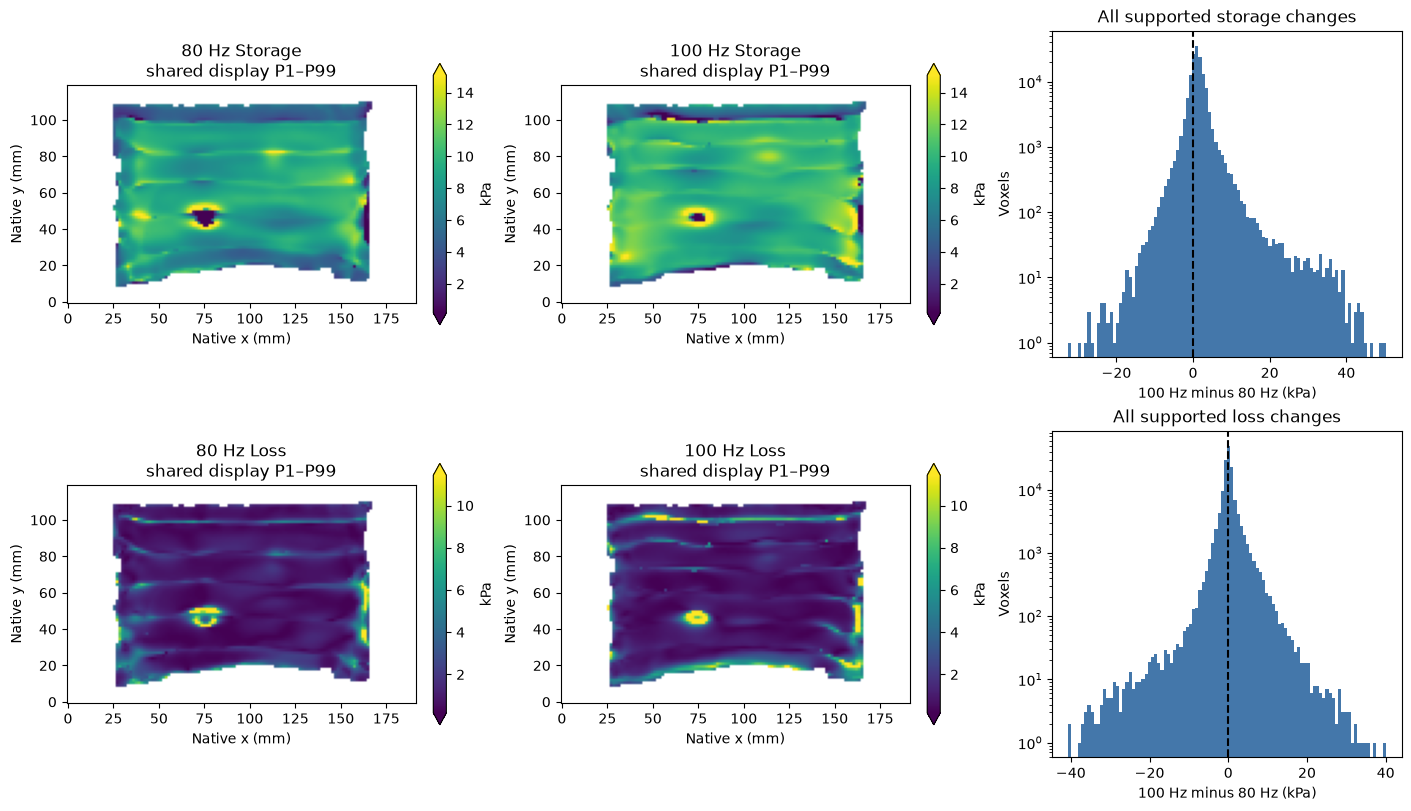

Negative storage fractions: [0.011338730753541625, 0.007798834323167654]
Loss phase quantiles, radians: [[0.0012572825383928739, 0.12417744932709236, 2.8993166903717924], [0.0003727268659998024, 0.10754464462467023, 2.701211976163418]]


In [6]:
fig,axes=plt.subplots(2,3,figsize=(14,8),layout='constrained')
for j,(extract,name) in enumerate([(np.real,'Storage'),(np.imag,'Loss')]):
    lim=tuple(np.quantile(extract(modulus)[:,support]/1000,[.01,.99]))
    for k,f in enumerate(frequencies):vis.panel(axes[j,k],np.where(support[:,:,zindex],extract(modulus[k,:,:,zindex])/1000,np.nan),f'{f:.0f} Hz {name}\nshared display P1–P99','kPa',limits=lim)
    change=extract(modulus[1]-modulus[0])[support]/1000
    axes[j,2].hist(change,bins=100,color='#4477aa');axes[j,2].axvline(0,color='black',ls='--');axes[j,2].set(title=f'All supported {name.lower()} changes',xlabel='100 Hz minus 80 Hz (kPa)',ylabel='Voxels');axes[j,2].set_yscale('log')
vis.save(fig,'05_measured_frequency_dependence');plt.show()
print('Negative storage fractions:',[float(np.mean(modulus[k].real[support]<0)) for k in range(2)])
print('Loss phase quantiles, radians:',[np.quantile(np.angle(modulus[k][support]),[0,.5,1]).tolist() for k in range(2)])

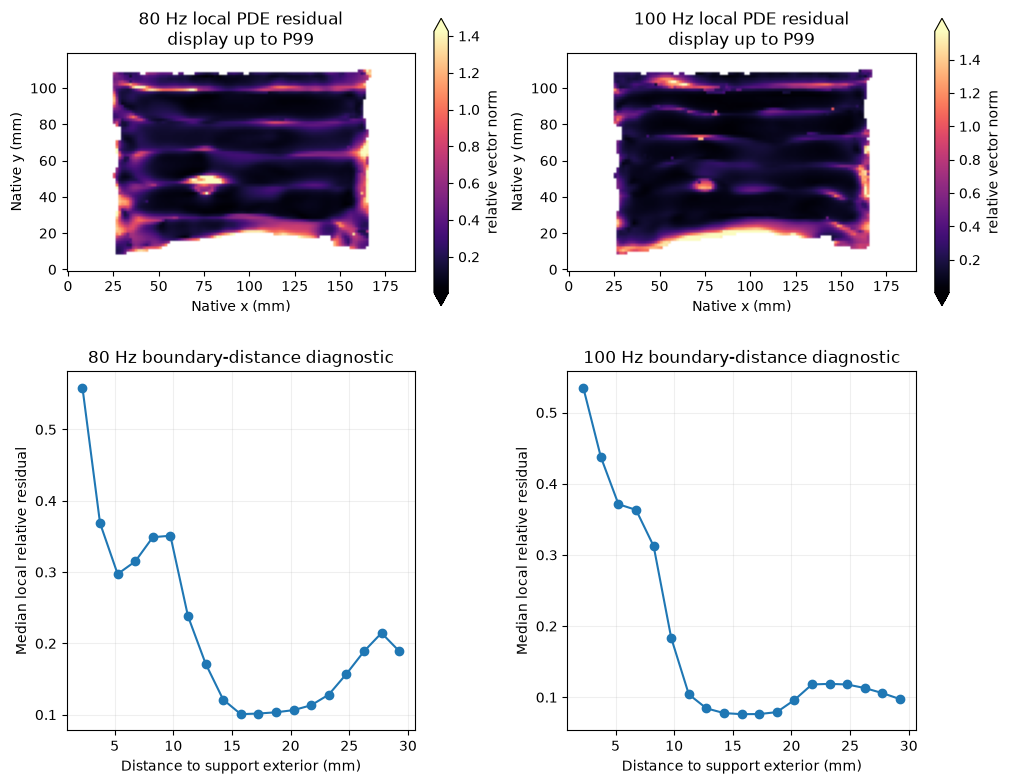

Distance is to binary exterior, not an inferred internal interface; low residual need not imply physical truth.


In [7]:
local_residual=[];distance=distance_transform_edt(support)*1.5
fig,axes=plt.subplots(2,2,figsize=(10,8),layout='constrained')
for k,f in enumerate(frequencies):
    forcing=1000*(2*np.pi*f)**2*filtered[k]
    norm=np.linalg.norm(forcing,axis=-1);r=np.linalg.norm(modulus[k,...,None]*laplacian[k]+forcing,axis=-1)/norm
    local_residual.append(r);limit=tuple(np.quantile(r[support],[0,.99]))
    vis.panel(axes[0,k],np.where(support[:,:,zindex],r[:,:,zindex],np.nan),f'{f:.0f} Hz local PDE residual\ndisplay up to P99','relative vector norm','magma',limit)
    edges=np.arange(0,31,1.5);medians=[np.median(r[support&(distance>=a)&(distance<b)]) if np.any(support&(distance>=a)&(distance<b)) else np.nan for a,b in zip(edges[:-1],edges[1:])]
    axes[1,k].plot((edges[1:]+edges[:-1])/2,medians,'o-');axes[1,k].set(title=f'{f:.0f} Hz boundary-distance diagnostic',xlabel='Distance to support exterior (mm)',ylabel='Median local relative residual');axes[1,k].grid(alpha=.2)
vis.save(fig,'06_boundary_and_model_residuals');plt.show()
print('Distance is to binary exterior, not an inferred internal interface; low residual need not imply physical truth.')

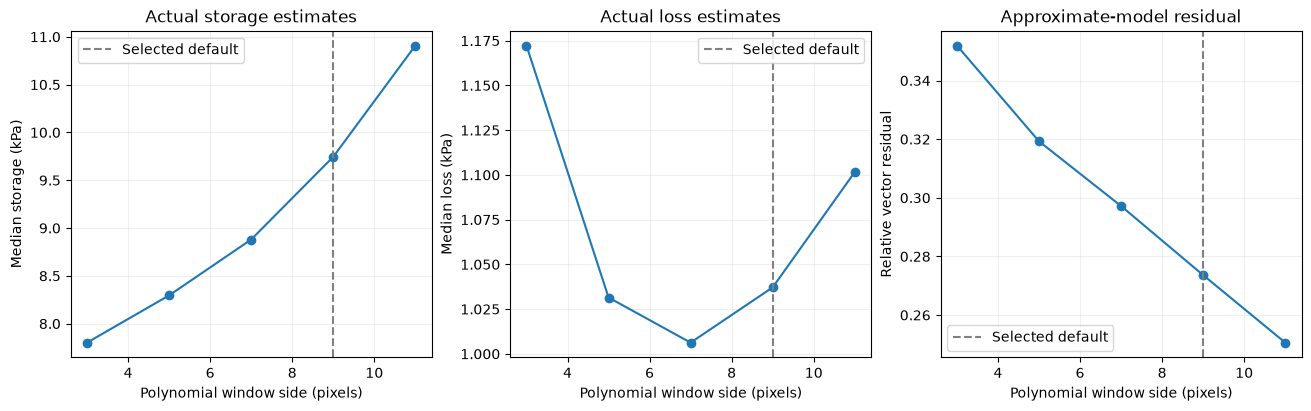

[
  {
    "window": 3,
    "seconds": 1.4790834000014002,
    "median_storage_kPa": 7.801532411039795,
    "median_loss_kPa": 1.1722943816983706,
    "relative_residual": 0.35194634437856365,
    "storage_nrmse_vs_default": 0.05287016379318393,
    "loss_nrmse_vs_default": 0.06133905292743336
  },
  {
    "window": 5,
    "seconds": 1.4117871000053128,
    "median_storage_kPa": 8.295736235922964,
    "median_loss_kPa": 1.0314743953323589,
    "relative_residual": 0.31926859898314586,
    "storage_nrmse_vs_default": 0.04556736887252299,
    "loss_nrmse_vs_default": 0.05398602726653453
  },
  {
    "window": 7,
    "seconds": 1.499765499989735,
    "median_storage_kPa": 8.880099532909007,
    "median_loss_kPa": 1.006255468922956,
    "relative_residual": 0.2971792759823187,
    "storage_nrmse_vs_default": 0.03350052963371047,
    "loss_nrmse_vs_default": 0.04003580794055058
  },
  {
    "window": 9,
    "seconds": 1.7625915999960853,
    "median_storage_kPa": 9.745138689592217,
    "medi

In [8]:
window_rows=[];window_maps={}
for size in [3,5,7,9,11]:
    begin=time.perf_counter();g,u,l=reconstruct(waves,frequencies,coordinates,support,kernel_size=size);seconds=time.perf_counter()-begin
    window_maps[size]=g
    window_rows.append(dict(window=size,seconds=seconds,median_storage_kPa=float(np.median(g[1].real[support])/1000),median_loss_kPa=float(np.median(g[1].imag[support])/1000),relative_residual=relative_residual(g[1],u[1],l[1],100.,support),storage_nrmse_vs_default=vis.scalar_metrics(g[1].real[support],modulus[1].real[support])['nrmse'],loss_nrmse_vs_default=vis.scalar_metrics(g[1].imag[support],modulus[1].imag[support])['nrmse']))
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,key,title,ylabel in zip(axes,['median_storage_kPa','median_loss_kPa','relative_residual'],['Actual storage estimates','Actual loss estimates','Approximate-model residual'],['Median storage (kPa)','Median loss (kPa)','Relative vector residual']):
    ax.plot([r['window'] for r in window_rows],[r[key] for r in window_rows],'o-');ax.axvline(9,color='gray',ls='--',label='Selected default');ax.set(title=title,xlabel='Polynomial window side (pixels)',ylabel=ylabel);ax.legend();ax.grid(alpha=.2)
vis.save(fig,'07_polynomial_window_sensitivity');plt.show();print(json.dumps(window_rows,indent=2))

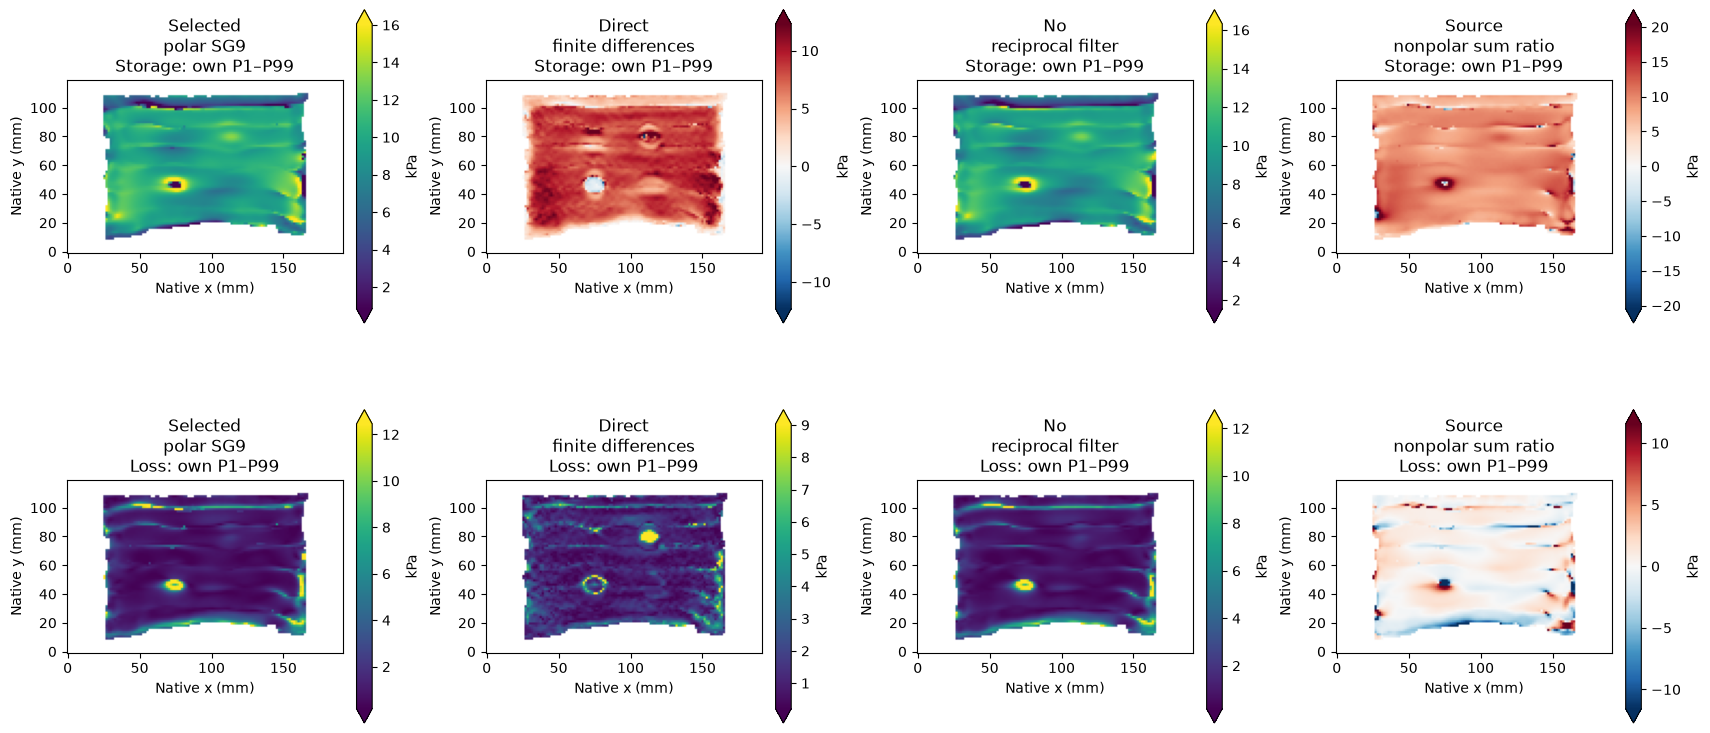

[
  {
    "method": "Selected polar SG9",
    "seconds": 1.7840790000045672,
    "relative_residual": 0.2736138916494486,
    "median_storage_kPa": 9.745138689592217,
    "median_loss_kPa": 1.0371665526037184,
    "negative_storage_fraction": 0.007798834323167654,
    "negative_loss_fraction": 0.0
  },
  {
    "method": "Direct finite differences",
    "seconds": 1.7108752999920398,
    "relative_residual": 0.34091762596761316,
    "median_storage_kPa": 8.078288171056313,
    "median_loss_kPa": 1.1387951110016905,
    "negative_storage_fraction": 0.025678076840642435,
    "negative_loss_fraction": 0.0
  },
  {
    "method": "No reciprocal filter",
    "seconds": 0.9792739999975311,
    "relative_residual": 0.27096995565716187,
    "median_storage_kPa": 9.764022813483615,
    "median_loss_kPa": 1.0318076299410766,
    "negative_storage_fraction": 0.005773073280004425,
    "negative_loss_fraction": 0.0
  },
  {
    "method": "Source nonpolar sum ratio",
    "seconds": 1.934078700011014,


In [9]:
comparison_rows=[];comparison_maps={}
settings=[('Selected polar SG9',{}),('Direct finite differences',dict(savgol=False)),('No reciprocal filter',dict(despeckle=False)),('Source nonpolar sum ratio',dict(polar=False))]
for name,options in settings:
    begin=time.perf_counter();g,u,l=reconstruct(waves,frequencies,coordinates,support,**options);seconds=time.perf_counter()-begin
    comparison_maps[name]=g
    comparison_rows.append(dict(method=name,seconds=seconds,relative_residual=relative_residual(g[1],u[1],l[1],100.,support),median_storage_kPa=float(np.median(g[1].real[support])/1000),median_loss_kPa=float(np.median(g[1].imag[support])/1000),negative_storage_fraction=float(np.mean(g[1].real[support]<0)),negative_loss_fraction=float(np.mean(g[1].imag[support]<0))))
fig,axes=plt.subplots(2,4,figsize=(17,8),layout='constrained')
for col,(name,g) in enumerate(comparison_maps.items()):
    for row,(extract,component) in enumerate([(np.real,'Storage'),(np.imag,'Loss')]):
        a=extract(g[1]);lim=tuple(np.quantile(a[support]/1000,[.01,.99]));image=np.where(support[:,:,zindex],a[:,:,zindex]/1000,np.nan)
        cmap='viridis'
        if lim[0]<0:lim=(-max(abs(lim[0]),abs(lim[1])),max(abs(lim[0]),abs(lim[1])));cmap='RdBu_r'
        vis.panel(axes[row,col],image,name.replace(' ','\n',1)+f'\n{component}: own P1–P99','kPa',cmap=cmap,limits=lim)
vis.save(fig,'08_actual_derivative_and_inverse_comparisons');plt.show();print(json.dumps(comparison_rows,indent=2))
print('Each diagnostic map has its own labeled display range; comparisons retain all numerical values. Nonpolar loss may be negative, exposing its different phase behavior.')

In [10]:
import importlib.util
spec=importlib.util.spec_from_file_location('independent_mre_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(root/'output/reconstruction.npz');assert report['passed'],report
Path('output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf-8');print(json.dumps(report,indent=2))
if os.environ.get('IMAGING_FIGURE_DIR'):
    private=Path(os.environ['IMAGING_FIGURE_DIR'])
    np.savez_compressed(private/'numerical_sources.npz',wave=waves,support=support,frequency=frequencies,original=original,fresh=modulus,filtered_wave=filtered,laplacian=laplacian,local_residual=np.stack(local_residual),distance_mm=distance,**{f'window_{k}':v for k,v in window_maps.items()},**{f'comparison_{k}':v for k,v in enumerate(comparison_maps.values())})
    (private/'scientific_measurements.json').write_text(json.dumps(dict(fresh_seconds=runtime,agreement=agreement,relative_residual=residuals,window_sensitivity=window_rows,comparisons=comparison_rows,judge=report),indent=2,allow_nan=False),encoding='utf-8')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "storage_0_ncc": 1.0,
    "storage_0_nrmse": 0.0,
    "loss_0_ncc": 1.0,
    "loss_0_nrmse": 0.0,
    "storage_1_ncc": 0.9999999999999999,
    "storage_1_nrmse": 0.0,
    "loss_1_ncc": 0.9999999999999998,
    "loss_1_nrmse": 0.0,
    "helmholtz_0": 0.2501509233855453,
    "helmholtz_1": 0.2736138916494486
  },
  "thresholds": {
    "storage_0_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "storage_0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "loss_0_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "loss_0_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "storage_1_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "storage_1_nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "loss_1_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "loss_1_nrmse": {
      "comparison": 

## 6. Conclusion
The fresh explicit local baseline reproduces the original's smoothed waves, planar Laplacians and complex modulus exactly on the bound acquisition. Storage and loss are evaluated independently at both frequencies. The genuine measured fields show frequency dependence, boundary-associated mismatch and sensitivity to smoothing and the phase formulation. These are useful diagnostics of a conditional direct inverse, not evidence of newly established phantom material truth.

The active benchmark is the selected quadratic9×9 polar baseline. Other displayed methods are fresh sensitivity reconstructions and retain their failures or signed estimates. No full PINN reproduction, hidden springpot truth, independently calibrated displacement, full3D mechanical PDE or unrestricted data-redistribution permission is claimed. Original source, paper, data hashes, physical checks, contract tests and the preprocessing-wrapper discrepancy are recorded in `test/validation.md`.